In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## accuracy-vs-parameters

**Figure 1: ImageNet top-1 accuracy versus number of parameters for EfficientNet-B0 to B7 and other ConvNets.** The dotted and dashed grey lines connect the hand-designed and the NAS models respectively. EfficientNet-B7 reaches 84.4% with 66M parameters, above AmoebaNet-C (83.5%) with 2.3× fewer parameters, and EfficientNet-B1 (79.2%, 7.8M) beats ResNet-152 (77.8%, 60M) while being 7.6× smaller.

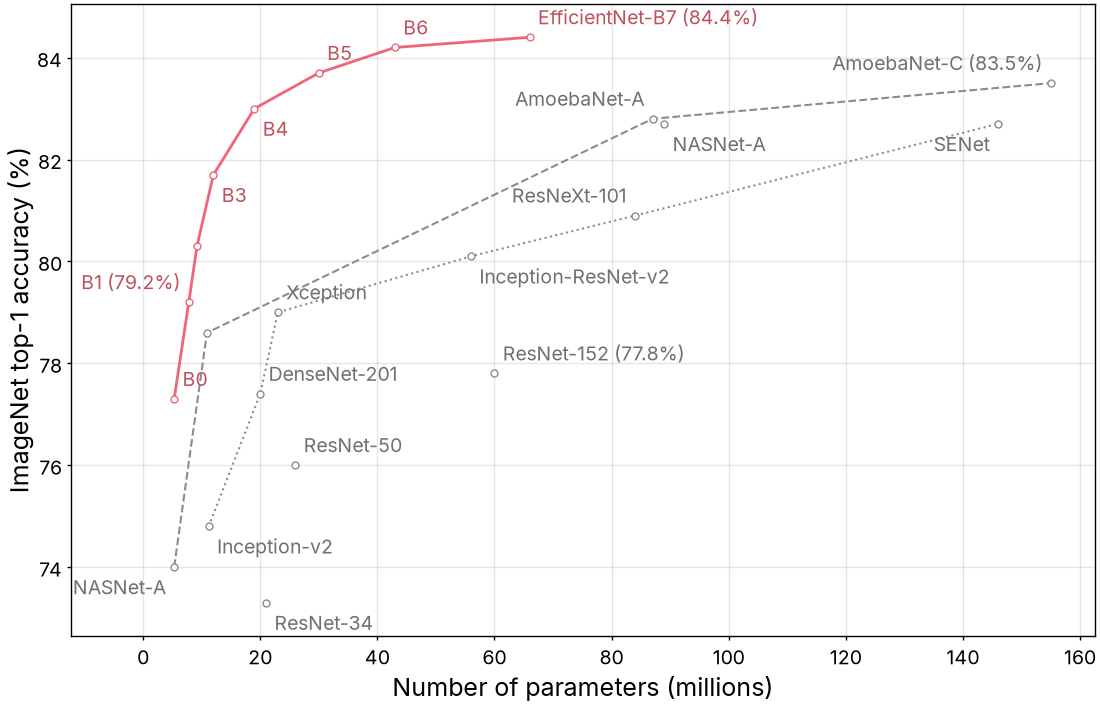

In [2]:
models = json.load(open("../data/accuracy-vs-parameters.json"))
for m in models:
    if m["model"] == "EfficientNet-B1":
        m["label_in_figure"] = "B1"
values_in_label = {"EfficientNet-B7", "EfficientNet-B1", "AmoebaNet-C", "ResNet-152"}
label_left = {"EfficientNet-B1", "NASNet-A (mobile)", "AmoebaNet-A", "ResNeXt-101", "SENet", "AmoebaNet-C"}
label_below = {"EfficientNet-B3", "EfficientNet-B4", "NASNet-A (mobile)", "Inception-v2", "NASNet-A (large)", "SENet",
               "Inception-ResNet-v2", "ResNet-34"}

fig, ax = plt.subplots(figsize=(5.5, 2))
fronts = [
    ("EfficientNet", colors["ours"], "-", plt.rcParams["lines.linewidth"]),
    ("hand-designed (dotted gray front)", colors["neutral"], ":", paper.dashed_width),
    ("NAS (dashed blue front)", colors["neutral"], "--", paper.dashed_width),
]
for family, color, linestyle, linewidth in fronts:
    points = sorted((m["params_millions"], m["top1_accuracy"]) for m in models if m["family"] == family)
    x, y = zip(*points)
    ax.plot(x, y, "o", linestyle=linestyle, linewidth=linewidth, color=color)
others = [m for m in models if m["family"] == "other (no line)"]
ax.plot([m["params_millions"] for m in others], [m["top1_accuracy"] for m in others], "o", color=colors["neutral"])

for m in models:
    if m["label_in_figure"] is None:
        continue
    color = colors["ours"] if m["family"] == "EfficientNet" else colors["neutral"]
    name = m["label_in_figure"]
    if m["model"] in values_in_label:
        name += f" ({m['top1_accuracy']:.1f}%)"
    left, below = m["model"] in label_left, m["model"] in label_below
    ax.annotate(name, (m["params_millions"], m["top1_accuracy"]), xytext=(-3 if left else 3, -3 if below else 3),
                textcoords="offset points", ha="right" if left else "left", va="top" if below else "bottom",
                fontsize=7, color=darken(color))

ax.set_xlabel("Number of parameters (millions)")
ax.set_ylabel("ImageNet top-1 accuracy (%)")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/accuracy-vs-parameters.pdf")
fig.savefig("../outputs/accuracy-vs-parameters.png")
plt.show()